### **Predictive Modeling and Risk Scoring for Bank Customer Churn**

**Background and Context**

• Customer Lifetime Value (CLV)

• Revenue stability

• Cross-sell and upsell potential

• Long-term competitiveness of retail banks

Traditional churn analysis explains why churn happened, but modern banking requires early identification of customers who are likely to churn, enabling:

• Proactive retention campaigns
• Personalized offers
• Targeted customer engagement

**Problem Statement**

Despite having rich customer-level data, banks often lack:

• Accurate churn prediction models

• Quantitative churn risk scores

• Explainable insights into churn drivers

**Primary Objectives**

• Predict customer churn with high accuracy

• Generate churn probability scores

• Identify key churn drivers

**Secondary Objectives**

• Reduce false positives in churn detection

• Improve interpretability of ML models

• Enable scenario-based churn risk analysis

**Analytical Methodology (Step-by-Step)**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

file_path = '/content/drive/MyDrive/European_Bank.csv'

df = pd.read_csv(file_path)

df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
df.shape

(10000, 14)

In [4]:
df.columns

Index(['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender',
       'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [6]:
df.describe()

,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,2025.0,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,0.0,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,2025.0,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2025.0,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,2025.0,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,2025.0,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,2025.0,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [7]:
df.isnull().sum()

,0
Year,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


No missing values found.

In [8]:
# Duplicate rows
df.duplicated().sum()

np.int64(0)

In [9]:
print("\nStatistical Summary:")
display(df.describe())


Statistical Summary:


,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,2025.0,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,0.0,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,2025.0,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2025.0,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,2025.0,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,2025.0,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,2025.0,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [10]:
print("\nFirst 5 Rows:")
display(df.head())


First 5 Rows:


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [11]:
# Remove non-informative columns
df = df.drop(columns=['CustomerId', 'Surname'])

# Check remaining columns
df.columns

Index(['Year', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure',
       'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited'],
      dtype='object')

In [12]:
print("Shape after removing columns:", df.shape)
display(df.head())

Shape after removing columns: (10000, 12)


,Year,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [13]:
# • Encode categorical variables:
# One-hot encoding (Geography, Gender)
# One-hot encode categorical variables
df = pd.get_dummies(
    df,
    columns=['Geography', 'Gender'],
    drop_first=True
)

# Check the updated dataset
df.head()

,Year,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,2025,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,2025,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,2025,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,2025,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,2025,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [14]:
# • Scale numerical features where required
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Features and target
X = df.drop('Exited', axis=1)
y = df['Exited']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
# identify numerical features
numerical_features = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'EstimatedSalary'
]

In [16]:
# Scale numerical features
scaler = StandardScaler()

X_train[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

X_test[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

In [17]:
# Check the result
X_train[numerical_features].head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
2151,1.058568,1.715086,0.684723,-1.226059,-0.910256,1.042084
8392,0.913626,-0.659935,-0.696202,0.413288,-0.910256,-0.623556
5006,1.079274,-0.184931,-1.731895,0.601687,0.808830,0.308128
4117,-0.929207,-0.184931,-0.005739,-1.226059,0.808830,-0.290199
7182,0.427035,0.955079,0.339492,0.548318,0.808830,0.135042


**Feature Engineering**

In [18]:
# Balance-to-Salary Ratio
df['BalanceSalaryRatio'] = df['Balance'] / df['EstimatedSalary']

# Display the new feature
df[['Balance', 'EstimatedSalary', 'BalanceSalaryRatio']].head()

,Balance,EstimatedSalary,BalanceSalaryRatio
0,0.00,101348.88,0.000000
1,83807.86,112542.58,0.744677
2,159660.80,113931.57,1.401375
3,0.00,93826.63,0.000000
4,125510.82,79084.10,1.587055


In [19]:
# safer version
df['BalanceSalaryRatio'] = (
    df['Balance'] / (df['EstimatedSalary'] + 1)
)

In [20]:
df['BalanceSalaryRatio'].describe()

,BalanceSalaryRatio
count,10000.000000
mean,3.790150
std,100.055758
min,0.000000
25%,0.000000
50%,0.746998
75%,1.514002
max,9770.883148


In [21]:
# product density indicator
df['ProductDensity'] = df['NumOfProducts'] / (df['Tenure'] + 1)

# check the new feature
df[['NumOfProducts', 'Tenure', 'ProductDensity']].head()

,NumOfProducts,Tenure,ProductDensity
0,1,2,0.333333
1,1,1,0.500000
2,3,8,0.333333
3,2,1,1.000000
4,1,2,0.333333


In [22]:
# Engagement Product Interaction
df['EngagementProductInteraction'] = (
    df['IsActiveMember'] * df['NumOfProducts']
)

# Check the new feature
df[['IsActiveMember', 'NumOfProducts',
    'EngagementProductInteraction']].head()

,IsActiveMember,NumOfProducts,EngagementProductInteraction
0,1,1,1
1,1,1,1
2,0,3,0
3,0,2,0
4,1,1,1


In [23]:
# Age-tenure interaction features
# Age Tenure Interaction = Age*Tenure
df['AgeTenureInteraction'] = df['Age'] * df['Tenure']

# Check the new feature
df[['Age', 'Tenure', 'AgeTenureInteraction']].head()

,Age,Tenure,AgeTenureInteraction
0,42,2,84
1,41,1,41
2,42,8,336
3,39,1,39
4,43,2,86


**Train–Test Strategy**

In [24]:
# • Stratified train-test split
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop('Exited', axis=1)
y = df['Exited']

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (8000, 16)
Testing set: (2000, 16)


In [25]:
print("Original:")
print(y.value_counts(normalize=True))

print("\nTraining:")
print(y_train.value_counts(normalize=True))

print("\nTesting:")
print(y_test.value_counts(normalize=True))

Original:
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

Training:
Exited
0    0.79625
1    0.20375
Name: proportion, dtype: float64

Testing:
Exited
0    0.7965
1    0.2035
Name: proportion, dtype: float64


In [26]:
# Preserve churn class distribution
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop('Exited', axis=1)
y = df['Exited']

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [27]:
print("Original distribution:")
print(y.value_counts(normalize=True))

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

Original distribution:
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

Training distribution:
Exited
0    0.79625
1    0.20375
Name: proportion, dtype: float64

Testing distribution:
Exited
0    0.7965
1    0.2035
Name: proportion, dtype: float64


In [28]:
#  Optional k-fold cross-validation
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

# Create Stratified K-Fold
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Cross-validation
cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=skf,
    scoring='accuracy'
)

print("CV Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

CV Scores: [0.803125 0.8125   0.821875 0.806875 0.80625 ]
Mean CV Accuracy: 0.810125
Standard Deviation: 0.006607287643201264


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [29]:
# Optional k-fold cross-validation
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

# 5-fold stratified cross-validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Model
model = LogisticRegression(max_iter=1000)

# Cross-validation on training data
scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=skf,
    scoring='accuracy'
)

print("Fold Accuracy:", scores)
print("Mean CV Accuracy:", scores.mean())
print("CV Standard Deviation:", scores.std())

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Fold Accuracy: [0.803125 0.8125   0.821875 0.806875 0.80625 ]
Mean CV Accuracy: 0.810125
CV Standard Deviation: 0.006607287643201264


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Train–Test Strategy**

In [30]:
# • Stratified train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [31]:
# Preserve churn class distribution
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [32]:
# optional k-fold cross-validation
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=skf,
    scoring='accuracy'
)

print("CV Scores:", scores)
print("Mean CV Accuracy:", scores.mean())

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

CV Scores: [0.803125 0.8125   0.821875 0.806875 0.80625 ]
Mean CV Accuracy: 0.810125


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Model Development**

In [33]:
# ==========================================
# LOGISTIC REGRESSION - BASELINE MODEL
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# 1. Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# 2. Train the model
logistic_model.fit(X_train, y_train)

# 3. Make predictions
y_pred_lr = logistic_model.predict(X_test)

# 4. Predict probabilities
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# ==========================================
# MODEL EVALUATION
# ==========================================

# Accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:",
      accuracy_lr)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

# ROC-AUC
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("\nROC-AUC Score:",
      roc_auc_lr)

Logistic Regression Accuracy: 0.8065

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.58      0.18      0.27       407

    accuracy                           0.81      2000
   macro avg       0.70      0.57      0.58      2000
weighted avg       0.77      0.81      0.76      2000


Confusion Matrix:
[[1540   53]
 [ 334   73]]

ROC-AUC Score: 0.7700026683077532


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [34]:
# 1. Decision Tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Decision Tree model
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Train the model
decision_tree.fit(X_train, y_train)

# Make predictions
y_pred_dt = decision_tree.predict(X_test)

# Evaluate the model
print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Accuracy: 0.8575

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.97      0.92      1593
           1       0.80      0.40      0.53       407

    accuracy                           0.86      2000
   macro avg       0.83      0.69      0.72      2000
weighted avg       0.85      0.86      0.84      2000


Confusion Matrix:
[[1552   41]
 [ 244  163]]


In [35]:
# 2. Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=10,
    class_weight="balanced"
)

# Train the model
random_forest.fit(X_train, y_train)

# Make predictions
y_pred_rf = random_forest.predict(X_test)

# Evaluate the model
print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 0.8385

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      1593
           1       0.60      0.64      0.62       407

    accuracy                           0.84      2000
   macro avg       0.75      0.77      0.76      2000
weighted avg       0.84      0.84      0.84      2000


Confusion Matrix:
[[1415  178]
 [ 145  262]]


In [36]:
# Compare Decision Tree and Random Forest
dt_accuracy = accuracy_score(y_test, y_pred_dt)
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Decision Tree Accuracy:", dt_accuracy)
print("Random Forest Accuracy:", rf_accuracy)

Decision Tree Accuracy: 0.8575
Random Forest Accuracy: 0.8385


In [37]:
# COMPARISION TABLE
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        dt_accuracy,
        rf_accuracy
    ]
})

print(model_comparison)

           Model  Accuracy
0  Decision Tree    0.8575
1  Random Forest    0.8385


In [38]:
# 4. Check Precision, Recall and F1-Score
from sklearn.metrics import classification_report

print("Decision Tree:")
print(classification_report(y_test, y_pred_dt))

print("\nRandom Forest:")
print(classification_report(y_test, y_pred_rf))

Decision Tree:
              precision    recall  f1-score   support

           0       0.86      0.97      0.92      1593
           1       0.80      0.40      0.53       407

    accuracy                           0.86      2000
   macro avg       0.83      0.69      0.72      2000
weighted avg       0.85      0.86      0.84      2000


Random Forest:
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      1593
           1       0.60      0.64      0.62       407

    accuracy                           0.84      2000
   macro avg       0.75      0.77      0.76      2000
weighted avg       0.84      0.84      0.84      2000



In [39]:
# Advanced Models
# Gradient Boosting
# ==========================================
# ADVANCED MODEL - GRADIENT BOOSTING
# ==========================================

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# 1. Create Gradient Boosting model
gradient_boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# 2. Train the model
gradient_boosting.fit(X_train, y_train)

# 3. Make predictions
y_pred_gb = gradient_boosting.predict(X_test)

# 4. Predict churn probabilities
y_prob_gb = gradient_boosting.predict_proba(X_test)[:, 1]

# ==========================================
# MODEL EVALUATION
# ==========================================

# Accuracy
accuracy_gb = accuracy_score(y_test, y_pred_gb)

print("Gradient Boosting Accuracy:",
      accuracy_gb)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

# ROC-AUC
roc_auc_gb = roc_auc_score(y_test, y_prob_gb)

print("\nGradient Boosting ROC-AUC:",
      roc_auc_gb)

Gradient Boosting Accuracy: 0.869

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.79      0.49      0.60       407

    accuracy                           0.87      2000
   macro avg       0.83      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000


Confusion Matrix:
[[1539   54]
 [ 208  199]]

Gradient Boosting ROC-AUC: 0.868227241108597


In [40]:

# =========================================================
# FIT GRADIENT BOOSTING MODEL - BANK CUSTOMER CHURN
# =========================================================

import sys
import sklearn
import joblib
import pandas as pd

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
from sklearn.utils.validation import check_is_fitted

print("Python version:", sys.version)
print("Scikit-learn version:", sklearn.__version__)

# 1. Verify that training and testing data already exist
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# 2. Create the Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# 3. Fit the model
gb_model.fit(X_train, y_train)

print("\nGradient Boosting model trained successfully!")

# 4. Predict churn class
y_pred_gb = gb_model.predict(X_test)

# 5. Predict churn probability (Exited = 1)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

# 6. Evaluate model
print("\nAccuracy:", round(
    accuracy_score(y_test, y_pred_gb), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_gb, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

print("\nROC-AUC:", round(
    roc_auc_score(y_test, y_prob_gb), 4
))

# 7. Display feature importance
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gb_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTop 10 Important Features:")
print(importance_df.head(10).to_string(index=False))

# 8. Save the fitted Gradient Boosting model
check_is_fitted(gb_model)

joblib.dump(gb_model, "churn_model.pkl", compress=3)

# 9. Verify that the saved file reloads successfully
verified_model = joblib.load("churn_model.pkl")
check_is_fitted(verified_model)

print("\nModel saved and reloaded successfully!")
print("Saved model type:", type(verified_model).__name__)
print("Number of features:", verified_model.n_features_in_)

if hasattr(verified_model, "feature_names_in_"):
    print("Feature names:", list(verified_model.feature_names_in_))

# 10. Download the model from Google Colab
from google.colab import files
files.download("churn_model.pkl")


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Scikit-learn version: 1.6.1
Training data shape: (8000, 16)
Testing data shape: (2000, 16)

Gradient Boosting model trained successfully!

Accuracy: 0.869

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.79      0.49      0.60       407

    accuracy                           0.87      2000
   macro avg       0.83      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000


Confusion Matrix:
[[1539   54]
 [ 208  199]]

ROC-AUC: 0.8682

Top 10 Important Features:
                     Feature  Importance
                         Age    0.385472
               NumOfProducts    0.284760
              IsActiveMember    0.075756
                     Balance    0.062069
           Geography_Germany    0.059430
EngagementProductInteraction    0.048913
          BalanceSalaryRatio    0.023278
        

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:

import pandas as pd
import numpy as np
import joblib

verified_model = joblib.load("churn_model.pkl")

feature_names = list(verified_model.feature_names_in_)
importances = verified_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances,
}).sort_values("Importance", ascending=False)

print(importance_df.to_string(index=False))

print("\nImportance total:", importances.sum())
print("Number of features:", len(feature_names))

assert len(feature_names) == 16
assert np.isclose(importances.sum(), 1.0)

print("Feature importance checks passed.")


                     Feature  Importance
                         Age    0.385472
               NumOfProducts    0.284760
              IsActiveMember    0.075756
                     Balance    0.062069
           Geography_Germany    0.059430
EngagementProductInteraction    0.048913
          BalanceSalaryRatio    0.023278
                 CreditScore    0.017132
             EstimatedSalary    0.016095
                 Gender_Male    0.013189
        AgeTenureInteraction    0.009066
              ProductDensity    0.003434
                   HasCrCard    0.000806
             Geography_Spain    0.000342
                      Tenure    0.000258
                        Year    0.000000

Importance total: 1.0
Number of features: 16
Feature importance checks passed.


In [42]:
# XGBoost (optional)
!pip install xgboost

In [43]:
from xgboost import XGBClassifier

In [44]:
# 2. XGBoost Model Code
#==========================================
# OPTIONAL ADVANCED MODEL - XGBOOST
# ==========================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric="logloss"
)

# Train the model
xgb_model.fit(X_train, y_train)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# Predict churn probability
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# ==========================================
# MODEL EVALUATION
# ==========================================

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Accuracy:", accuracy_xgb)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

# ROC-AUC
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("\nXGBoost ROC-AUC:", roc_auc_xgb)

XGBoost Accuracy: 0.8685

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.80      0.47      0.59       407

    accuracy                           0.87      2000
   macro avg       0.84      0.72      0.76      2000
weighted avg       0.86      0.87      0.86      2000


Confusion Matrix:
[[1544   49]
 [ 214  193]]

XGBoost ROC-AUC: 0.8678917746714357


In [45]:
print("Features used by scaler:")
print(scaler.feature_names_in_)

Features used by scaler:
['CreditScore' 'Age' 'Tenure' 'Balance' 'NumOfProducts' 'EstimatedSalary']


In [46]:
print("Features used by model:")
print(X_train.columns.tolist())

Features used by model:
['Year', 'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProductInteraction', 'AgeTenureInteraction']


In [47]:
print("MODEL FEATURES:")
print(X_train.columns.tolist())

print("\nSCALER FEATURES:")
print(scaler.feature_names_in_)

MODEL FEATURES:
['Year', 'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProductInteraction', 'AgeTenureInteraction']

SCALER FEATURES:
['CreditScore' 'Age' 'Tenure' 'Balance' 'NumOfProducts' 'EstimatedSalary']


In [48]:

# ============================================
# BANK CUSTOMER CHURN: MODEL COMPARISON
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Define models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

# Add XGBoost if it is installed
try:
    from xgboost import XGBClassifier

    models["XGBoost"] = XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        eval_metric="logloss",
        random_state=42
    )
except ImportError:
    print("XGBoost is not installed. Skipping XGBoost.")

# 2. Train and evaluate every model
results = []
fitted_models = {}
confusion_matrices = {}

for name, model in models.items():

    print(f"\nTraining: {name}")

    model.fit(X_train, y_train)

    # Predict class labels
    y_pred = model.predict(X_test)

    # Predict probability of churn (class 1)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    fitted_models[name] = model
    confusion_matrices[name] = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

# 3. Display comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

print("\n========== MODEL COMPARISON ==========")
print(results_df.round(4).to_string(index=False))

# 4. Save results
results_df.to_csv("model_comparison_results.csv", index=False)

print("\nResults saved to model_comparison_results.csv")



Training: Logistic Regression

Training: Decision Tree

Training: Random Forest

Training: Gradient Boosting

Training: XGBoost

========== MODEL COMPARISON ==========
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
  Gradient Boosting    0.8690     0.7866  0.4889    0.6030   0.8682
            XGBoost    0.8655     0.7717  0.4816    0.5930   0.8668
      Random Forest    0.8675     0.7910  0.4742    0.5929   0.8521
Logistic Regression    0.8065     0.5735  0.1916    0.2873   0.7734
      Decision Tree    0.7830     0.4682  0.4889    0.4784   0.6735

Results saved to model_comparison_results.csv


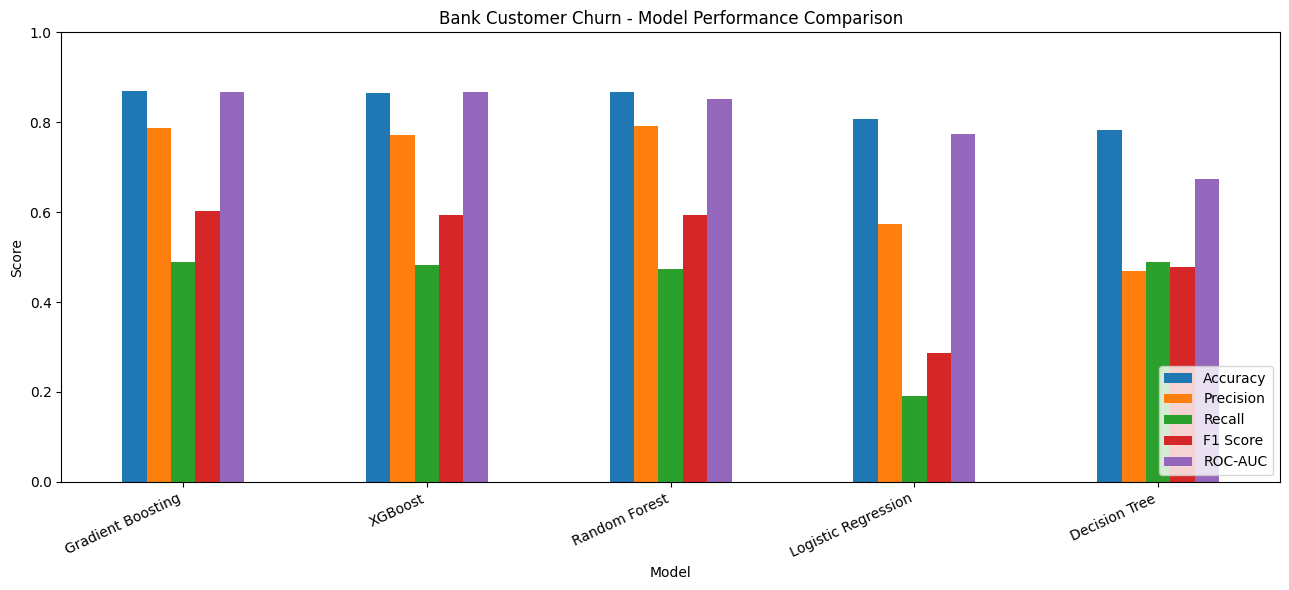

In [49]:

# Compare evaluation metrics
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

ax = (
    results_df.set_index("Model")[metrics]
    .plot(kind="bar", figsize=(13, 6))
)

ax.set_title("Bank Customer Churn - Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


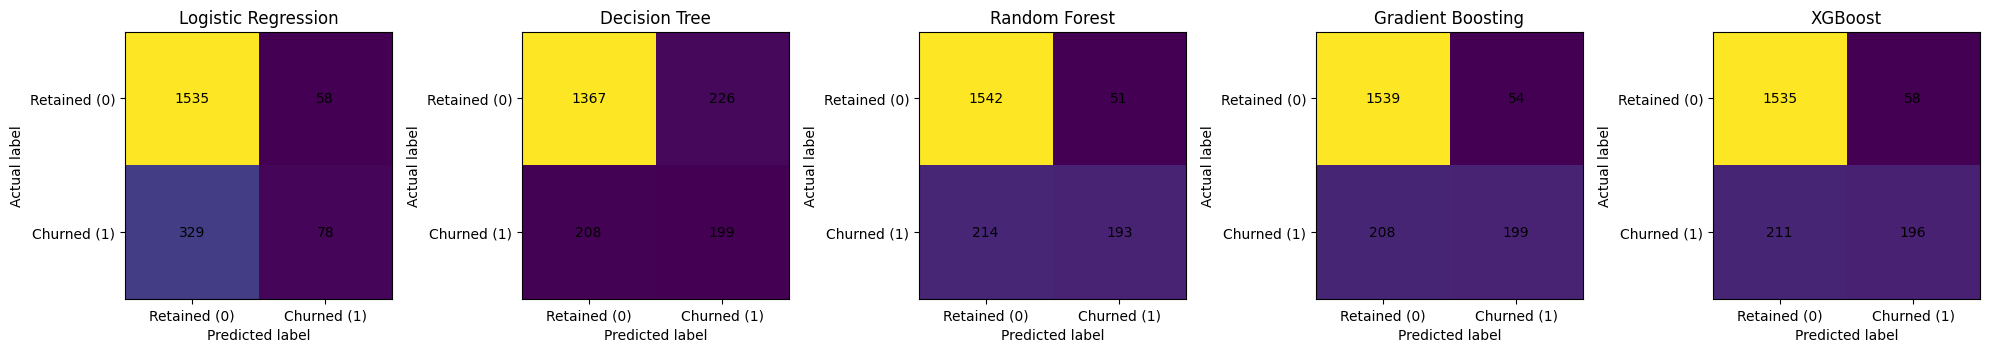

In [50]:

fig, axes = plt.subplots(
    1, len(confusion_matrices),
    figsize=(4 * len(confusion_matrices), 4)
)

if len(confusion_matrices) == 1:
    axes = [axes]

for ax, (name, cm) in zip(axes, confusion_matrices.items()):
    ax.imshow(cm, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_xticks([0, 1], labels=["Retained (0)", "Churned (1)"])
    ax.set_yticks([0, 1], labels=["Retained (0)", "Churned (1)"])

    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]),
                    ha="center", va="center")

plt.tight_layout()
plt.show()


In [51]:
# print best model
best_f1_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

best_auc_model = results_df.loc[
    results_df["ROC-AUC"].idxmax()
]

print("Best model by churn F1-score:")
print(best_f1_model[["Model", "F1 Score", "Recall", "Precision"]])

print("\nBest model by ROC-AUC:")
print(best_auc_model[["Model", "ROC-AUC", "Accuracy"]])


Best model by churn F1-score:
Model        Gradient Boosting
F1 Score               0.60303
Recall                0.488943
Precision             0.786561
Name: 0, dtype: object

Best model by ROC-AUC:
Model       Gradient Boosting
ROC-AUC              0.868227
Accuracy                0.869
Name: 0, dtype: object


In [52]:
# fit gradient boosting model
import sys
import sklearn
import joblib

print("Python version:", sys.version)
print("Scikit-learn version:", sklearn.__version__)
print("Joblib version:", joblib.__version__)

# Import required libraries
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
import joblib

# Create the Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Fit the model on training data
gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

# Predict customer churn
y_pred_gb = gb_model.predict(X_test)

# Predict churn probabilities
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

# Evaluate model
print("\nAccuracy:", round(accuracy_score(y_test, y_pred_gb), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

print("\nROC-AUC Score:", round(roc_auc_score(y_test, y_prob_gb), 4))


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Scikit-learn version: 1.6.1
Joblib version: 1.6.0
Gradient Boosting model trained successfully!

Accuracy: 0.869

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.79      0.49      0.60       407

    accuracy                           0.87      2000
   macro avg       0.83      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000


Confusion Matrix:
[[1539   54]
 [ 208  199]]

ROC-AUC Score: 0.8682


In [53]:
import pickle

# Save trained model
with open("churn_model.pkl", "wb") as file:
    pickle.dump(model, file)

# Save scaler
with open("scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

# Save feature column names
with open("feature_columns.pkl", "wb") as file:
    pickle.dump(X_train.columns.tolist(), file)

print("Model files saved successfully!")

Model files saved successfully!


In [54]:

# Save the trained model
joblib.dump(gb_model, "churn_model.pkl")

print("Saved fitted Gradient Boosting model as churn_model.pkl")


Saved fitted Gradient Boosting model as churn_model.pkl


In [55]:
import joblib
from sklearn.utils.validation import check_is_fitted

check_is_fitted(gb_model)

joblib.dump(gb_model, "churn_model.pkl", compress=3)

# Verify that the saved file can be reloaded in Colab
test_model = joblib.load("churn_model.pkl")
check_is_fitted(test_model)

print("Model saved and verified successfully.")
print("Model type:", type(test_model).__name__)
print("Number of features:", test_model.n_features_in_)

Model saved and verified successfully.
Model type: GradientBoostingClassifier
Number of features: 16


In [56]:
from google.colab import files
files.download("churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model Explainability

In [57]:
# 1.Random Forest – Feature Importance
import pandas as pd

# Get feature importance
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest.feature_importances_
})

# Sort from highest to lowest
rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Add ranking
rf_importance["Rank"] = range(1, len(rf_importance) + 1)

# Display top 10
print("Random Forest Feature Importance:")
print(rf_importance.head(10))

Random Forest Feature Importance:
                        Feature  Importance  Rank
0                           Age    0.270541     1
1                 NumOfProducts    0.154963     2
2                       Balance    0.078577     3
3  EngagementProductInteraction    0.074613     4
4          AgeTenureInteraction    0.066112     5
5            BalanceSalaryRatio    0.063752     6
6               EstimatedSalary    0.058778     7
7                   CreditScore    0.058503     8
8             Geography_Germany    0.048507     9
9                ProductDensity    0.037746    10


In [58]:
# 2. Decision Tree – Feature Importance
dt_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": decision_tree.feature_importances_
})

dt_importance = dt_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

dt_importance["Rank"] = range(1, len(dt_importance) + 1)

print("Decision Tree Feature Importance:")
print(dt_importance.head(10))

Decision Tree Feature Importance:
                Feature  Importance  Rank
0                   Age    0.407926     1
1         NumOfProducts    0.327230     2
2        IsActiveMember    0.132353     3
3     Geography_Germany    0.060290     4
4               Balance    0.038508     5
5    BalanceSalaryRatio    0.013859     6
6       EstimatedSalary    0.009717     7
7  AgeTenureInteraction    0.004081     8
8           CreditScore    0.003741     9
9        ProductDensity    0.002295    10


In [59]:
#3. Gradient Boosting – Feature Importance
gb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gradient_boosting.feature_importances_
})

gb_importance = gb_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

gb_importance["Rank"] = range(1, len(gb_importance) + 1)

print("Gradient Boosting Feature Importance:")
print(gb_importance.head(10))

Gradient Boosting Feature Importance:
                        Feature  Importance  Rank
0                           Age    0.385472     1
1                 NumOfProducts    0.284760     2
2                IsActiveMember    0.075756     3
3                       Balance    0.062069     4
4             Geography_Germany    0.059430     5
5  EngagementProductInteraction    0.048913     6
6            BalanceSalaryRatio    0.023278     7
7                   CreditScore    0.017132     8
8               EstimatedSalary    0.016095     9
9                   Gender_Male    0.013189    10


In [60]:
# 4. XGBoost – Feature Importance
xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

xgb_importance["Rank"] = range(1, len(xgb_importance) + 1)

print("XGBoost Feature Importance:")
print(xgb_importance.head(10))

XGBoost Feature Importance:
                        Feature  Importance  Rank
0  EngagementProductInteraction    0.248020     1
1                           Age    0.154715     2
2                 NumOfProducts    0.140736     3
3                IsActiveMember    0.136685     4
4             Geography_Germany    0.092712     5
5                       Balance    0.045879     6
6                   Gender_Male    0.043817     7
7            BalanceSalaryRatio    0.032199     8
8                     HasCrCard    0.017565     9
9                   CreditScore    0.016053    10


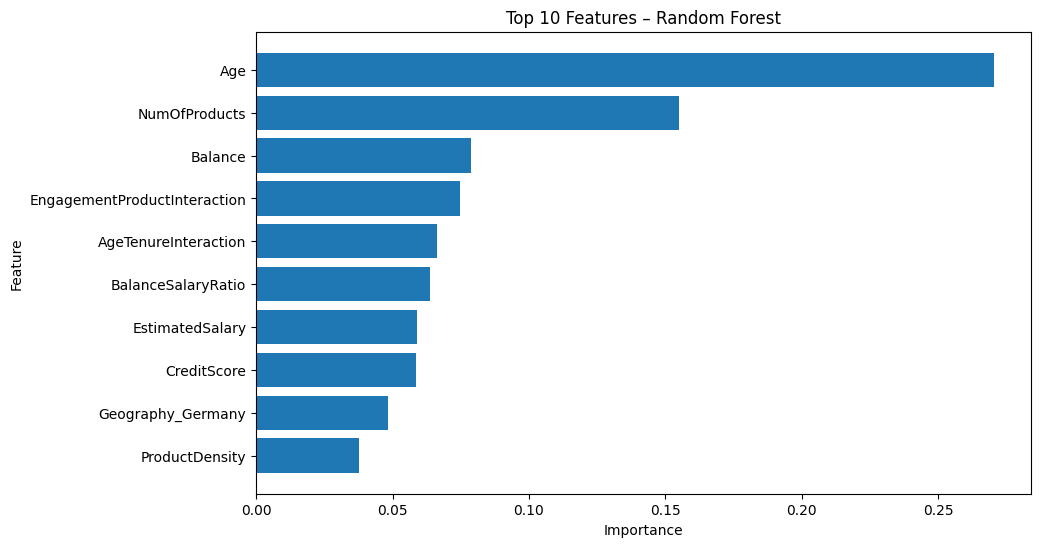

In [61]:
# 5. Visualize Feature Importance
import matplotlib.pyplot as plt

top_features = rf_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features – Random Forest")

plt.gca().invert_yaxis()

plt.show()

In [62]:
# 7. Compare Feature Importance Across Models
# ==========================================
# COMPARE FEATURE IMPORTANCE ACROSS MODELS
# ==========================================

import pandas as pd

# Create comparison DataFrame
importance_comparison = pd.DataFrame({
    "Feature": X_train.columns,

    "Decision Tree":
        decision_tree.feature_importances_,

    "Random Forest":
        random_forest.feature_importances_,

    "Gradient Boosting":
        gradient_boosting.feature_importances_,

    "XGBoost":
        xgb_model.feature_importances_
})

# Display all features
print("Feature Importance Comparison:")
print(importance_comparison)

Feature Importance Comparison:
                         Feature  Decision Tree  Random Forest  \
0                           Year       0.000000       0.000000   
1                    CreditScore       0.003741       0.058503   
2                            Age       0.407926       0.270541   
3                         Tenure       0.000000       0.025478   
4                        Balance       0.038508       0.078577   
5                  NumOfProducts       0.327230       0.154963   
6                      HasCrCard       0.000000       0.007326   
7                 IsActiveMember       0.132353       0.029846   
8                EstimatedSalary       0.009717       0.058778   
9              Geography_Germany       0.060290       0.048507   
10               Geography_Spain       0.000000       0.008778   
11                   Gender_Male       0.000000       0.016482   
12            BalanceSalaryRatio       0.013859       0.063752   
13                ProductDensity       0.0022

In [63]:
# feature ranking
# Calculate average feature importance
importance_comparison["Average Importance"] = (
    importance_comparison[
        [
            "Decision Tree",
            "Random Forest",
            "Gradient Boosting",
            "XGBoost"
        ]
    ].mean(axis=1)
)

# Rank features
feature_ranking = (
    importance_comparison[
        ["Feature", "Average Importance"]
    ]
    .sort_values(
        by="Average Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# Add rank
feature_ranking.insert(
    0,
    "Rank",
    range(1, len(feature_ranking) + 1)
)

print(feature_ranking)

    Rank                       Feature  Average Importance
0      1                           Age            0.304663
1      2                 NumOfProducts            0.226922
2      3                IsActiveMember            0.093660
3      4  EngagementProductInteraction            0.092886
4      5             Geography_Germany            0.065235
5      6                       Balance            0.056258
6      7            BalanceSalaryRatio            0.033272
7      8               EstimatedSalary            0.024818
8      9                   CreditScore            0.023857
9     10          AgeTenureInteraction            0.023823
10    11                   Gender_Male            0.018372
11    12                ProductDensity            0.014305
12    13                        Tenure            0.009950
13    14                     HasCrCard            0.006424
14    15               Geography_Spain            0.005554
15    16                          Year            0.0000

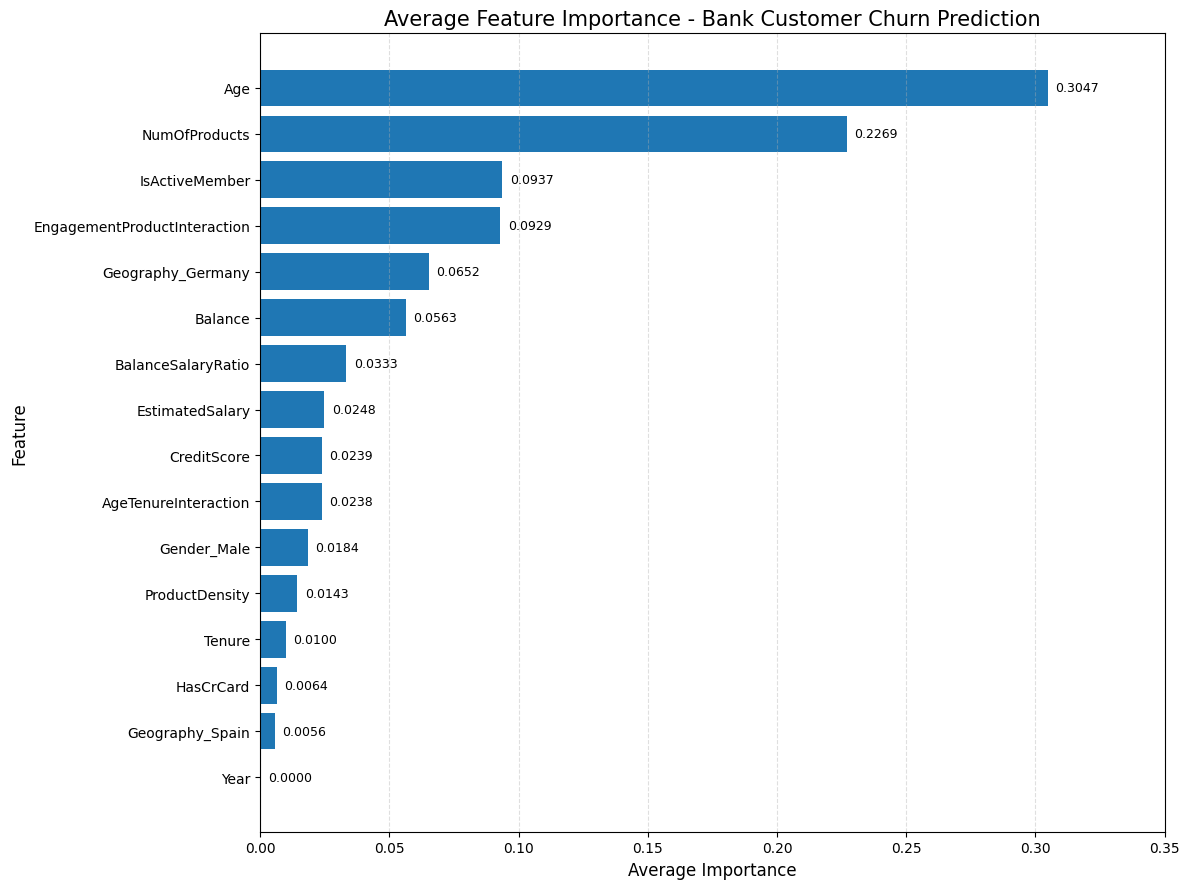

In [81]:

import pandas as pd
import matplotlib.pyplot as plt

# Feature importance data
data = {
    "Rank": list(range(1, 17)),
    "Feature": [
        "Age",
        "NumOfProducts",
        "IsActiveMember",
        "EngagementProductInteraction",
        "Geography_Germany",
        "Balance",
        "BalanceSalaryRatio",
        "EstimatedSalary",
        "CreditScore",
        "AgeTenureInteraction",
        "Gender_Male",
        "ProductDensity",
        "Tenure",
        "HasCrCard",
        "Geography_Spain",
        "Year"
    ],
    "Average Importance": [
        0.304663,
        0.226922,
        0.093660,
        0.092886,
        0.065235,
        0.056258,
        0.033272,
        0.024818,
        0.023857,
        0.023823,
        0.018372,
        0.014305,
        0.009950,
        0.006424,
        0.005554,
        0.000000
    ]
}

df = pd.DataFrame(data)

# Plot horizontal bar chart
plt.figure(figsize=(12, 9))

bars = plt.barh(
    df["Feature"][::-1],
    df["Average Importance"][::-1]
)

# Add values at the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.4f}",
        va="center",
        fontsize=9
    )

plt.title(
    "Average Feature Importance - Bank Customer Churn Prediction",
    fontsize=15
)
plt.xlabel("Average Importance", fontsize=12)
plt.ylabel("Feature", fontsize=12)

plt.xlim(0, 0.35)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save the chart for your project report
plt.savefig(
    "average_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [64]:
# SHAP analysis
!pip install shap

In [65]:
import shap
import matplotlib.pyplot as plt

In [66]:
# Decision Tree – SHAP Analysis
# ==========================================
# SHAP ANALYSIS - DECISION TREE
# ==========================================

# Create explainer
explainer_dt = shap.TreeExplainer(decision_tree)

# Calculate SHAP values
shap_values_dt = explainer_dt.shap_values(X_test)

print("Decision Tree SHAP values calculated.")

Decision Tree SHAP values calculated.


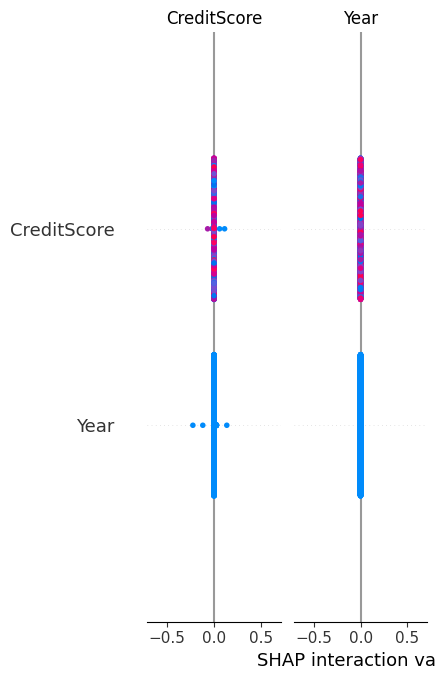

In [67]:
shap.summary_plot(
    shap_values_dt,
    X_test
)

In [68]:
# 2. Random Forest – SHAP Analysis
# ==========================================
# SHAP ANALYSIS - RANDOM FOREST
# ==========================================

explainer_rf = shap.TreeExplainer(random_forest)

shap_values_rf = explainer_rf.shap_values(X_test)

print("Random Forest SHAP values calculated.")

Random Forest SHAP values calculated.


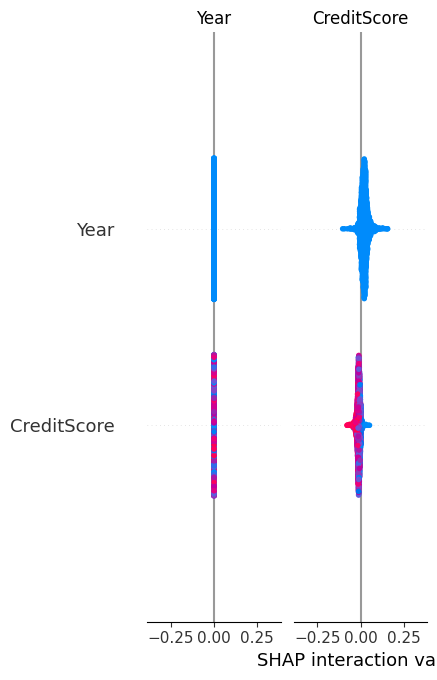

In [69]:
shap.summary_plot(
    shap_values_rf,
    X_test
)

In [70]:
# ==========================================
# SHAP ANALYSIS - GRADIENT BOOSTING
# ==========================================

explainer_gb = shap.TreeExplainer(gradient_boosting)

shap_values_gb = explainer_gb.shap_values(X_test)

print("Gradient Boosting SHAP values calculated.")

Gradient Boosting SHAP values calculated.


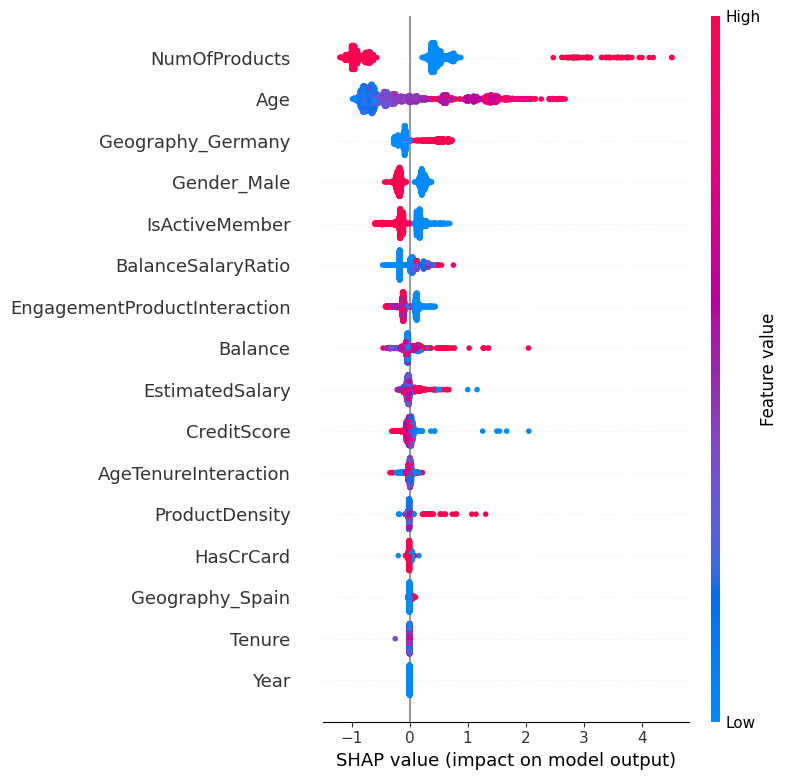

In [71]:
shap.summary_plot(
    shap_values_gb,
    X_test
)

In [72]:
# SHAP Analysis for XGBoost

import shap

# Create SHAP explainer
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test)

print("SHAP values calculated successfully.")

SHAP values calculated successfully.


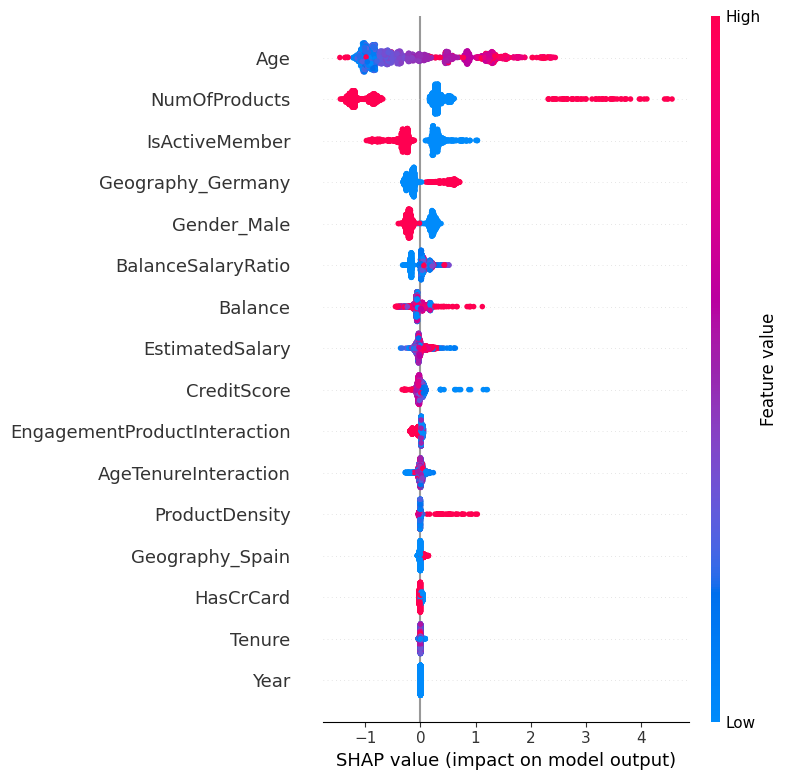

In [73]:
shap.summary_plot(
    shap_values,
    X_test
)

In [74]:
# partial dependence plot
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

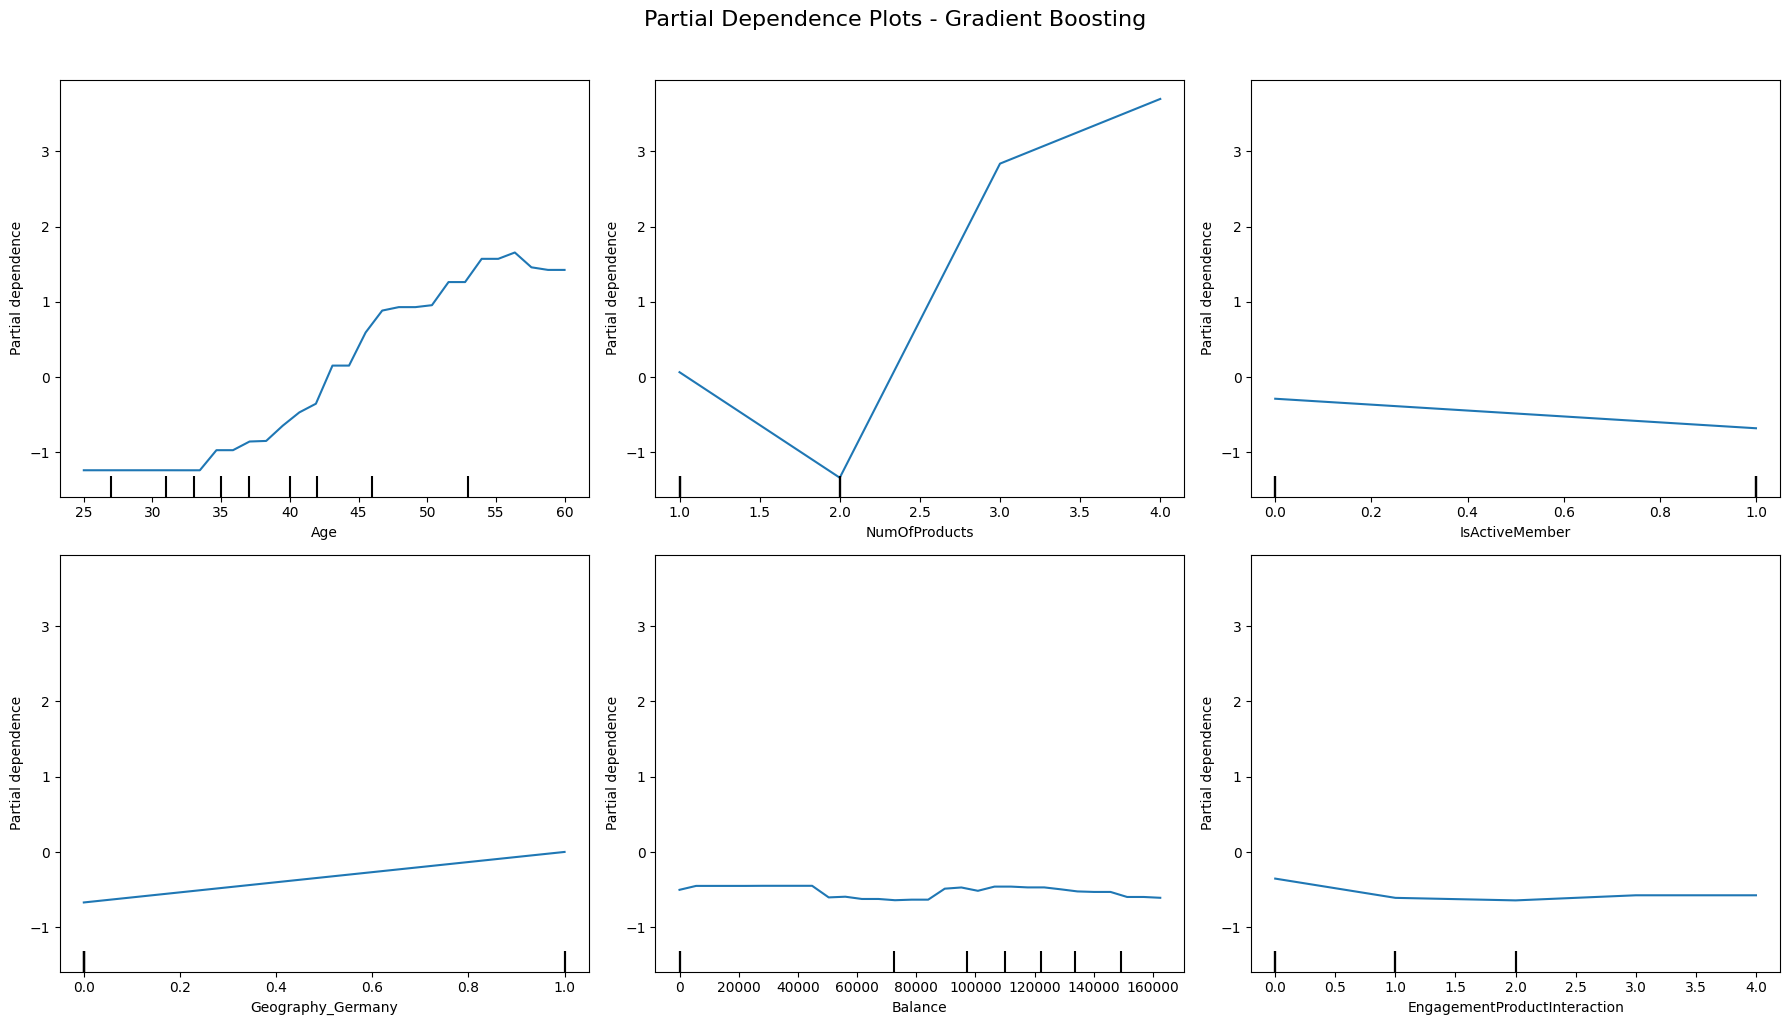

In [82]:

import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

# Select important features for PDP analysis
features_to_plot = [
    "Age",
    "NumOfProducts",
    "IsActiveMember",
    "Geography_Germany",
    "Balance",
    "EngagementProductInteraction"
]

# Verify that all selected features exist
features_to_plot = [
    feature for feature in features_to_plot
    if feature in X_train.columns
]

# Create Partial Dependence Plots
fig, ax = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 10)
)

PartialDependenceDisplay.from_estimator(
    gb_model,
    X_train,
    features=features_to_plot,
    kind="average",
    response_method="auto",
    ax=ax.ravel(),
    grid_resolution=30
)

plt.suptitle(
    "Partial Dependence Plots - Gradient Boosting",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


**Explainability is critical for regulatory compliance and business trust.**

Explainability is critical for regulatory compliance and business trust because organizations need to understand why a machine-learning model makes a particular prediction, especially when decisions affect customers.
In this customer churn prediction project, explainability helps stakeholders understand which customer characteristics contribute most to the predicted churn risk.
Key techniques used are:
- Feature Importance: Identifies the features that have the greatest influence on the model's predictions.
- SHAP Analysis: Shows both the importance and direction of each feature's contribution to individual predictions.
- Partial Dependence Plots (PDP): Shows how changes in an individual feature affect the model's average predicted churn probability.
Business Benefits
1. Transparency: Business teams can understand how the model reaches its predictions.
2. Trust: Stakeholders are more likely to trust and adopt a model whose decisions can be explained.
3. Regulatory Compliance: Explainable models support requirements for transparency, accountability, and responsible AI.
4. Fairness Monitoring: Explainability can help identify whether sensitive or potentially biased features are influencing predictions.
5. Better Decisions: Customer-retention teams can understand the factors associated with higher churn risk and design appropriate interventions.